# N3b — Arm D, full augmentation, long schedule

### What N3 established

Comparing arm C's own two decode rules isolated the mechanism from model quality:

| level | C soft-LL | C soft-LL + erasure | erasure contributes |
|---|---|---|---|
| 0.00 | 97.48% | 97.44% | **-0.04** |
| 0.50 | 39.60% | 60.08% | **+20.48** |

Erasure weighting is free when nothing is occluded and worth up to +20.5 pp when it is.
The erasure head separates occluded from visible cells by **0.888**, against the published
decoder's 0.004.

The remaining deficit was training, not method: C's bit head sat 2.06 pp below the published
decoder at level 0.00 after 40 CPU epochs on 26k crops.

### What changes here

**Arm D** — unmasked bit loss (like B) plus the erasure head (like C). N3 masked C's bit loss on
occluded cells, and that cost bit accuracy in the mid-range: at level 0.20, B scored 93.12% against
C's 83.41%. Partial occlusion still leaves exploitable signal, so training the network to guess
pays. The robustness comes from the erasure head, so the two should be decoupled.

**Full augmentation** — 4 rotations x 2 flips, applied on the fly, with bits *and* the occlusion
mask transformed to match. Verified against the published decoder: bit agreement 1.0000 for
rot90 k=1,2 and for both flips. This is 8x effective data and was missing from N3.

**5 occlusion samples per marker** from a richer level set including the 0.10-0.25 mid-range where
N3 was weakest.

**200 epochs, patience 20, GPU.**

Target: arm D matches the published decoder at level 0.00 within noise while keeping the
occlusion gains.

## 0. Do not touch video_6 yet

`video_6` is the held-out viewpoint. N3b is still development — arm D is a new design being
tested, and if it underperforms there will be an N3c. Evaluating on the held-out set now and
iterating afterwards means it is no longer held out, and the final numbers stop being an honest
estimate of generalisation.

Run everything here on the dev viewpoints. Touch `video_6` exactly once, when the design is
frozen and you are generating the numbers that go in the paper.

## 1. Setup

In [2]:
!pip -q install opencv-contrib-python==4.10.0.84 h5py 2>&1 | tail -1
print(">>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 40.0 MB/s eta 0:00:00
>>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.


### 1b. Port module

In [1]:
%%writefile /content/deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Writing /content/deeparuco_port.py


In [3]:
import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE  = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives'
CKPT  = f'{BASE}/ckpt_n3b'; os.makedirs(CKPT, exist_ok=True); os.makedirs(WORK, exist_ok=True)
sys.path.insert(0, '/content')

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits
from deeparuco_port import load_weights, NumpyDecoder

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
print('torch', torch.__version__, '| device', DEV_)
if DEV_.type != 'cuda':
    print('\n*** CPU RUNTIME. 200 epochs x 3 arms will be very slow.')
    print('*** Runtime > Change runtime type > T4 GPU, then re-run from cell 1.')

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT, STRIDE = splits['dev'], splits['heldout'][0], splits['benchmark_stride']
Wk  = load_weights(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
FLY = f'{WORK}/flyingarucov2'
if not os.path.isdir(FLY):
    os.makedirs(FLY, exist_ok=True)
    subprocess.run(['tar','-xzf',f'{CACHE}/flyingarucov2.tar.gz','-C',FLY], check=True)
fly_json = sorted(glob.glob(f'{FLY}/**/*.json', recursive=True))
print('\ndev:', DEV, '| HELD OUT (untouched):', HELDOUT)
print('Flying-ArUco v2 annotations:', len(fly_json))

Mounted at /content/drive
torch 2.11.0+cu128 | device cuda

dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | HELD OUT (untouched): video_6
Flying-ArUco v2 annotations: 2500


## 2. Shared pipeline (identical to N2/N3)

In [4]:
r_int = lambda v: int(round(v))
LEVELS = [0.0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]

def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))

def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)

def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out

def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)

def occlude_frame(img, corners, level, key, mid):
    if level <= 0: return img, np.zeros(img.shape[:2], np.uint8)
    rng = np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode()))
    side = int(rng.integers(0,4)); x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)
    if c>a and d>b: out[b:d,a:c] = 127; mk[b:d,a:c] = 255
    return out, mk

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out
print('pipeline ready')

pipeline ready


## 3. Training crops — 5 occlusion samples per marker

Level set now includes 0.10 and 0.25, covering the mid-range where N3's arm C was weakest.

In [5]:
def bits_for(mid, rot, conv):
    b = CB[mid]; k = rot if conv in (0,1) else -rot
    return np.rot90(b, k) if conv in (0,2) else np.rot90(b, -k)

ref = NumpyDecoder(Wk)
probe = []
for jp in fly_json[:60]:
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    for m in json.load(open(jp))['markers'][:4]:
        x32,_ = prepare(img, np.zeros(img.shape[:2],np.uint8), get_corners(m))
        if x32 is None: continue
        probe.append((ref(x32), int(m['id']), int(m.get('rot', m.get('rotation', 0)))))
scores = {c: np.mean([np.mean((p>0.5).astype(np.uint8)==bits_for(i,r,c)) for p,i,r in probe])
          for c in range(4)}
CONV = max(scores, key=scores.get)
print('rotation convention scores:', {k: round(float(v),4) for k,v in scores.items()})
assert scores[CONV] > 0.90, 'no rotation convention agrees — labels would be wrong'
print(f'chosen convention {CONV} ({scores[CONV]:.4f})\n')

OCC_TRAIN = [0.0, 0.10, 0.20, 0.25, 0.35, 0.45, 0.55]
N_SAMPLES = 5
X, Ybit, Yocc = [], [], []
t0 = time.time()
for n, jp in enumerate(fly_json):
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    key = os.path.basename(jp)
    for m in json.load(open(jp))['markers']:
        cn, mid = get_corners(m), int(m['id'])
        if mid >= 250: continue
        bits = bits_for(mid, int(m.get('rot', m.get('rotation', 0))), CONV)
        rng = np.random.default_rng(zlib.crc32(f'train|{key}|{mid}'.encode()))
        for L in rng.choice(OCC_TRAIN, N_SAMPLES, replace=False):
            oi, om = occlude_frame(img, cn, float(L), key, mid)
            x32, occ = prepare(oi, om, cn)
            if x32 is None: continue
            X.append((x32*255).astype(np.uint8)); Ybit.append(bits); Yocc.append(occ)
    if n % 500 == 0: print(f'  {n}/{len(fly_json)} ({time.time()-t0:.0f}s) crops={len(X)}')

X = np.stack(X); Ybit = np.stack(Ybit).astype(np.float32); Yocc = np.stack(Yocc).astype(np.float32)
print(f'\n{len(X)} crops ({X.nbytes/1e6:.0f} MB) | mean occluded cells {Yocc.sum((1,2)).mean():.2f}')
print(f'clean {(Yocc.sum((1,2))==0).mean():.1%} | effective size with 8x aug: {len(X)*8:,}')
idx = np.random.default_rng(42).permutation(len(X)); cut = int(0.9*len(X))
tr, va = idx[:cut], idx[cut:]
print(f'train {len(tr)} | val {len(va)}')

rotation convention scores: {0: 0.9912, 1: 0.769, 2: 0.769, 3: 0.9912}
chosen convention 0 (0.9912)

  0/2500 (0s) crops=40
  500/2500 (10s) crops=12950
  1000/2500 (21s) crops=25935
  1500/2500 (31s) crops=39070
  2000/2500 (42s) crops=51900

64840 crops (66 MB) | mean occluded cells 7.00
clean 32.1% | effective size with 8x aug: 518,720
train 58356 | val 6484


## 4. Rotation / flip augmentation

Image, bit labels and occlusion mask all transform together. Verified against the published
decoder offline: `np.rot90(img,k)` matches `np.rot90(bits,k)` at agreement 1.0000 for k=1,2 and
both flips are exact. The assertion below re-checks it on this data.

In [6]:
def augment(xb, bb, ob, rng):
    """xb (N,32,32) uint8, bb/ob (N,6,6). Applies the same transform to all three."""
    k  = rng.integers(0, 4)
    fl = rng.integers(0, 3)          # 0 none, 1 lr, 2 ud
    if k:
        xb = np.rot90(xb, k, axes=(1,2)); bb = np.rot90(bb, k, axes=(1,2)); ob = np.rot90(ob, k, axes=(1,2))
    if fl == 1:
        xb = xb[:, :, ::-1]; bb = bb[:, :, ::-1]; ob = ob[:, :, ::-1]
    elif fl == 2:
        xb = xb[:, ::-1, :]; bb = bb[:, ::-1, :]; ob = ob[:, ::-1, :]
    return np.ascontiguousarray(xb), np.ascontiguousarray(bb), np.ascontiguousarray(ob)

# the published decoder must read augmented crops as the augmented labels
chk = tr[:400]
agree_plain = np.mean([np.mean((ref(X[i]/255.0)>0.5).astype(np.uint8)==Ybit[i]) for i in chk])
ax_, ab_, _ = augment(X[chk], Ybit[chk], Yocc[chk], np.random.default_rng(3))
agree_aug = np.mean([np.mean((ref(ax_[n]/255.0)>0.5).astype(np.uint8)==ab_[n]) for n in range(len(chk))])
print(f'bit agreement, un-augmented : {agree_plain:.4f}')
print(f'bit agreement, augmented    : {agree_aug:.4f}')
assert abs(agree_aug - agree_plain) < 0.05, \
    'augmentation breaks the label correspondence — bits/mask are not transforming with the image'
print('augmentation label correspondence OK')

bit agreement, un-augmented : 0.8690
bit agreement, augmented    : 0.8685
augmentation label correspondence OK


## 5. Models and the three arms

| arm | bit loss | erasure head |
|---|---|---|
| B | all cells | no |
| C | visible cells only (masked) | yes |
| **D** | all cells | yes |

D is the candidate: B's bit supervision plus C's erasure head. C is retained as the ablation
showing why masking was the wrong choice.

In [7]:
class SpatialPReLU(nn.Module):
    def __init__(s, c, h, w):
        super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s, x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)

class Decoder(nn.Module):
    def __init__(s, out_ch=1):
        super().__init__()
        s.c1 = nn.Conv2d(1,8,5); s.p1 = SpatialPReLU(8,28,28)
        s.c2 = nn.Conv2d(8,4,3); s.p2 = SpatialPReLU(4,12,12)
        s.c3 = nn.Conv2d(4,out_ch,1); s.out_ch = out_ch
    def forward(s, x):
        x = F.max_pool2d(s.p1(s.c1(x)), 2)
        x = F.max_pool2d(s.p2(s.c2(x)), 2)
        x = s.c3(x)
        return (x[:,0], x[:,1]) if s.out_ch == 2 else (x[:,0], None)

ARMS = {'B': dict(out_ch=1, mask_bits=False),
        'C': dict(out_ch=2, mask_bits=True),
        'D': dict(out_ch=2, mask_bits=False)}
for a, cfg in ARMS.items():
    m = Decoder(cfg['out_ch']); y = m(torch.zeros(2,1,32,32))
    assert y[0].shape == (2,6,6)
    print(f"arm {a}: out_ch={cfg['out_ch']} mask_bits={cfg['mask_bits']} "
          f"params={sum(p.numel() for p in m.parameters())}")

arm B: out_ch=1 mask_bits=False params=7353
arm C: out_ch=2 mask_bits=True params=7358
arm D: out_ch=2 mask_bits=False params=7358


## 6. Training — 200 epochs, patience 20

In [8]:
EPOCHS, PATIENCE, BS = 200, 20, 256

def run_epoch(model, ids, cfg, opt=None, rng=None, bs=BS):
    train = opt is not None
    model.train(train); tot = n = 0
    order = np.random.permutation(ids) if train else ids
    with torch.set_grad_enabled(train):
        for s in range(0, len(order), bs):
            b = order[s:s+bs]
            xb, bb, ob = X[b], Ybit[b], Yocc[b]
            if train: xb, bb, ob = augment(xb, bb, ob, rng)
            xb = torch.tensor(xb, dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            bb = torch.tensor(bb).to(DEV_); ob = torch.tensor(ob).to(DEV_)
            logit, elogit = model(xb)
            if cfg['mask_bits']:
                vis = 1.0 - ob
                loss = (F.binary_cross_entropy_with_logits(logit, bb, reduction='none')*vis
                        ).sum()/vis.sum().clamp(min=1)
            else:
                loss = F.binary_cross_entropy_with_logits(logit, bb)
            if cfg['out_ch'] == 2:
                loss = loss + F.binary_cross_entropy_with_logits(elogit, ob)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss)*len(b); n += len(b)
    return tot/n

models, curves = {}, {}
for arm, cfg in ARMS.items():
    torch.manual_seed(42); rng = np.random.default_rng(42)
    net = Decoder(cfg['out_ch']).to(DEV_)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    best, bad, hist, t0 = 1e9, 0, [], time.time()
    for ep in range(EPOCHS):
        trl = run_epoch(net, tr, cfg, opt, rng)
        vl  = run_epoch(net, va, cfg)
        sch.step(vl); hist.append((trl, vl))
        if vl < best - 1e-5:
            best, bad = vl, 0; torch.save(net.state_dict(), f'{CKPT}/arm_{arm}.pt')
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f'  arm {arm}: early stop at epoch {ep}'); break
        if ep % 20 == 0:
            print(f'  arm {arm} ep{ep:3d}  train {trl:.4f}  val {vl:.4f}  ({time.time()-t0:.0f}s)')
    net.load_state_dict(torch.load(f'{CKPT}/arm_{arm}.pt')); net.eval()
    models[arm], curves[arm] = net, hist
    print(f'arm {arm}: best val {best:.4f}  |  {time.time()-t0:.0f}s\n')

/tmp/ipykernel_7047/1023194312.py:25: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss)*len(b); n += len(b)


  arm B ep  0  train 0.4748  val 0.2859  (2s)
  arm B ep 20  train 0.1653  val 0.1665  (19s)
  arm B ep 40  train 0.1587  val 0.1579  (36s)
  arm B ep 60  train 0.1561  val 0.1563  (52s)
  arm B ep 80  train 0.1539  val 0.1545  (69s)
  arm B ep100  train 0.1532  val 0.1536  (86s)
  arm B ep120  train 0.1527  val 0.1531  (102s)
  arm B ep140  train 0.1525  val 0.1533  (119s)
  arm B: early stop at epoch 152
arm B: best val 0.1527  |  130s

  arm C ep  0  train 0.9703  val 0.4332  (1s)
  arm C ep 20  train 0.1173  val 0.1201  (20s)
  arm C ep 40  train 0.0967  val 0.0986  (40s)
  arm C ep 60  train 0.0890  val 0.0921  (59s)
  arm C ep 80  train 0.0856  val 0.0890  (78s)
  arm C ep100  train 0.0832  val 0.0866  (97s)
  arm C ep120  train 0.0812  val 0.0846  (117s)
  arm C ep140  train 0.0798  val 0.0843  (136s)
  arm C ep160  train 0.0788  val 0.0829  (155s)
  arm C ep180  train 0.0787  val 0.0828  (174s)
  arm C: early stop at epoch 181
arm C: best val 0.0827  |  175s

  arm D ep  0  tra

## 7. Erasure head quality

In [9]:
print(f"{'arm':>5}{'thresh':>9}{'precision':>11}{'recall':>9}{'F1':>8}{'separation':>13}")
print('-'*55)
for arm in ('C','D'):
    net = models[arm]
    with torch.no_grad():
        xb = torch.tensor(X[va], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
        parts = [net(xb[s:s+8192]) for s in range(0, len(xb), 8192)]
        E = torch.sigmoid(torch.cat([p[1] for p in parts])).cpu().numpy()
    T = Yocc[va].astype(bool)
    sep = E[T].mean() - E[~T].mean()
    for t in (0.5,):
        p = E > t; tp = (p & T).sum()
        pr, rc = tp/max(p.sum(),1), tp/max(T.sum(),1)
        print(f'{arm:>5}{t:>9.1f}{pr:>11.3f}{rc:>9.3f}{2*pr*rc/max(pr+rc,1e-9):>8.3f}{sep:>13.4f}')
print("\npublished decoder confidence separation: 0.004 (N2)")

  arm   thresh  precision   recall      F1   separation
-------------------------------------------------------
    C      0.5      0.954    0.959   0.956       0.9186
    D      0.5      0.972    0.971   0.971       0.9455

published decoder confidence separation: 0.004 (N2)


## 8. Evaluation on the dev viewpoints

In [10]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def decode_published(x32, chunk=2048):
    out=[]
    for s in range(0,len(x32),chunk):
        x = np.asarray(x32[s:s+chunk],np.float32)[...,None]
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)

def decode_torch(net, x32, chunk=8192):
    ps, es = [], []
    with torch.no_grad():
        for s in range(0,len(x32),chunk):
            xb = torch.tensor(x32[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)
            lo, el = net(xb)
            ps.append(torch.sigmoid(lo).cpu().numpy())
            es.append(torch.sigmoid(el).cpu().numpy() if el is not None else np.zeros((len(lo),6,6),np.float32))
    return np.concatenate(ps), np.concatenate(es)

def dec_hard(P):
    O=(P>0.5).astype(np.float32).reshape(len(P),36)
    D=np.stack([O.sum(1,keepdims=True)+ROT[k].sum(1)[None,:]-2*O@ROT[k].T for k in range(4)])
    return D.min(0).argmin(1)
def dec_soft(P, Wt=None):
    """Wt: per-cell weight in [0,1]. Wt=1-E gives soft-erasure decoding."""
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    if Wt is not None:
        w = Wt.reshape(len(P),36); LP = LP*w; LQ = LQ*w
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)

EV = {L: {'x':[], 'id':[]} for L in LEVELS}
t0=time.time()
for vid in DEV:                                   # video_6 deliberately excluded
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            for L in LEVELS:
                oi, om = occlude_frame(img, cn, L, key, mid)
                x32, _ = prepare(oi, om, cn)
                if x32 is None: continue
                EV[L]['x'].append(x32); EV[L]['id'].append(mid)
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for L in LEVELS:
    EV[L]['x'] = np.stack(EV[L]['x']); EV[L]['id'] = np.array(EV[L]['id'])
print(f'{len(EV[0.0]["id"])} markers per level')

  video_1 (20s)
  video_2 (36s)
  video_3 (55s)
  video_4 (73s)
  video_5 (88s)
12276 markers per level


In [11]:
rows = []
for L in LEVELS:
    x32, ids = EV[L]['x'], EV[L]['id']
    Pa = decode_published(x32)
    Pb, _  = decode_torch(models['B'], x32)
    Pc, Ec = decode_torch(models['C'], x32)
    Pd, Ed = decode_torch(models['D'], x32)
    rows.append(dict(level=L,
        A_hard=(dec_hard(Pa)==ids).mean(), A_soft=(dec_soft(Pa)==ids).mean(),
        B_soft=(dec_soft(Pb)==ids).mean(),
        C_soft=(dec_soft(Pc)==ids).mean(), C_eras=(dec_soft(Pc,1-Ec)==ids).mean(),
        D_soft=(dec_soft(Pd)==ids).mean(), D_eras=(dec_soft(Pd,1-Ed)==ids).mean()))

print('ID ACCURACY — dev viewpoints, all rules unbounded nearest-codeword')
print(f"{'lvl':>5}{'A hard':>9}{'A soft':>9}{'B soft':>9}{'C eras':>9}{'D soft':>9}{'D eras':>9}"
      f"{'D-A':>8}{'eras adds':>11}")
print('-'*78)
for r in rows:
    print(f"{r['level']:>5.2f}{r['A_hard']:>9.2%}{r['A_soft']:>9.2%}{r['B_soft']:>9.2%}"
          f"{r['C_eras']:>9.2%}{r['D_soft']:>9.2%}{r['D_eras']:>9.2%}"
          f"{(r['D_eras']-r['A_soft'])*100:>7.1f}p{(r['D_eras']-r['D_soft'])*100:>10.1f}p")

ID ACCURACY — dev viewpoints, all rules unbounded nearest-codeword
  lvl   A hard   A soft   B soft   C eras   D soft   D eras     D-A  eras adds
------------------------------------------------------------------------------
 0.00   99.38%   99.54%   99.74%   99.68%   99.41%   99.41%   -0.1p       0.0p
 0.10   99.04%   99.28%   99.70%   99.07%   98.87%   98.87%   -0.4p       0.0p
 0.20   90.80%   91.45%   99.31%   98.34%   96.03%   96.63%    5.2p       0.6p
 0.30   73.95%   75.65%   97.02%   95.15%   89.06%   90.41%   14.8p       1.4p
 0.40   46.65%   49.43%   93.63%   89.80%   85.04%   86.42%   37.0p       1.4p
 0.50   18.47%   22.53%   83.77%   75.22%   75.81%   76.70%   54.2p       0.9p
 0.60    4.38%    6.21%   55.44%   44.36%   51.88%   53.59%   47.4p       1.7p


## 9. Verdict

Two conditions must both hold. The clean case must not regress, and the erasure head must be
what produces the gain.

clean regression, D-erasure vs A-soft : -0.12 pp   (target: within ~0.5)
max erasure contribution (D vs D-soft): +1.71 pp
max D vs B (erasure head over bits)   : -0.33 pp
max D vs C (unmasked over masked bits): +9.23 pp

Clean case fixed but the erasure gain shrank. Check the erasure head F1 in section 7.


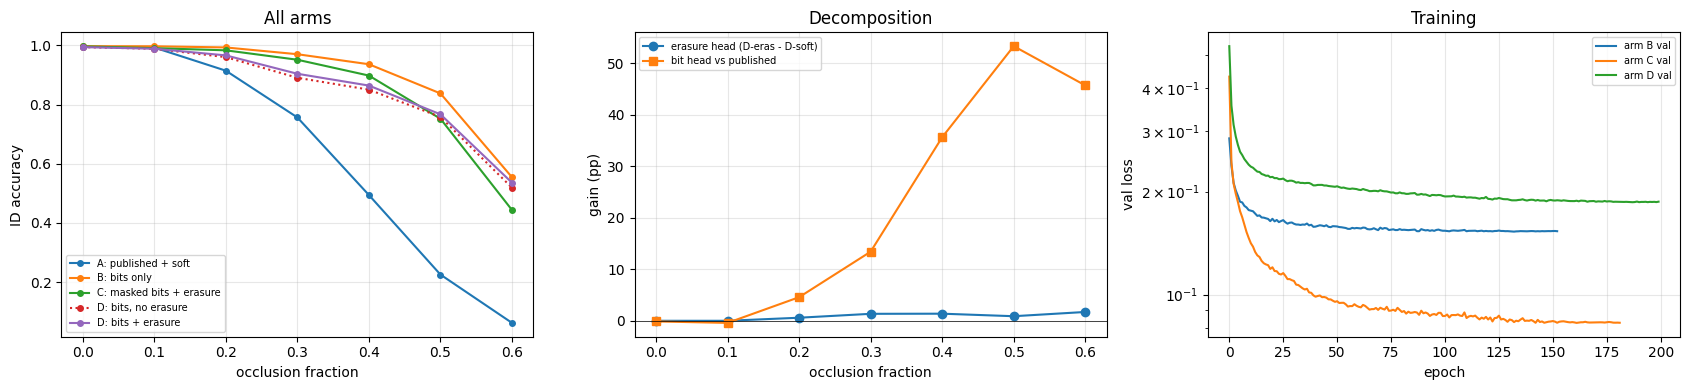


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n3b_results.json  |  checkpoints /content/drive/MyDrive/aruco_p2/ckpt_n3b


In [12]:
clean   = rows[0]
regress = (clean['A_soft'] - clean['D_eras'])*100
eras_add = max(r['D_eras']-r['D_soft'] for r in rows)*100
d_vs_b   = max(r['D_eras']-r['B_soft'] for r in rows)*100
d_vs_c   = max(r['D_eras']-r['C_eras'] for r in rows)*100

print(f'clean regression, D-erasure vs A-soft : {-regress:+.2f} pp   (target: within ~0.5)')
print(f'max erasure contribution (D vs D-soft): {eras_add:+.2f} pp')
print(f'max D vs B (erasure head over bits)   : {d_vs_b:+.2f} pp')
print(f'max D vs C (unmasked over masked bits): {d_vs_c:+.2f} pp\n')

if regress <= 0.5 and eras_add >= 10:
    print('READY. Arm D matches the published decoder on clean markers and gains substantially')
    print('under occlusion. Freeze the design, then run the held-out video_6 evaluation ONCE.')
elif regress <= 0.5:
    print('Clean case fixed but the erasure gain shrank. Check the erasure head F1 in section 7.')
elif eras_add >= 10:
    print(f'Erasure mechanism works but arm D still loses {regress:.2f} pp on clean markers.')
    print('Most likely still undertrained — check whether early stopping fired well before 200')
    print('epochs, and whether train and val losses are still falling together.')
else:
    print('Neither condition met. Do not proceed to video_6; diagnose before iterating further.')

fig, ax = plt.subplots(1,3, figsize=(17,4))
L_=[r['level'] for r in rows]
for k,lbl,st in [('A_soft','A: published + soft','-'),('B_soft','B: bits only','-'),
                 ('C_eras','C: masked bits + erasure','-'),('D_soft','D: bits, no erasure',':'),
                 ('D_eras','D: bits + erasure','-')]:
    ax[0].plot(L_, [r[k] for r in rows], marker='o', ms=4, ls=st, label=lbl)
ax[0].set_xlabel('occlusion fraction'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('All arms'); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)

ax[1].plot(L_, [(r['D_eras']-r['D_soft'])*100 for r in rows], marker='o', label='erasure head (D-eras - D-soft)')
ax[1].plot(L_, [(r['D_soft']-r['A_soft'])*100 for r in rows], marker='s', label='bit head vs published')
ax[1].axhline(0, color='k', lw=.5); ax[1].set_xlabel('occlusion fraction')
ax[1].set_ylabel('gain (pp)'); ax[1].set_title('Decomposition'); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)

for arm in ARMS:
    ax[2].plot([h[1] for h in curves[arm]], label=f'arm {arm} val')
ax[2].set_xlabel('epoch'); ax[2].set_ylabel('val loss'); ax[2].set_yscale('log')
ax[2].set_title('Training'); ax[2].legend(fontsize=7); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

json.dump({'rows':[{k:(float(v) if isinstance(v,(int,float,np.floating)) else v) for k,v in r.items()} for r in rows],
           'clean_regression_pp': float(regress), 'erasure_contribution_pp': float(eras_add),
           'D_vs_B_pp': float(d_vs_b), 'D_vs_C_pp': float(d_vs_c),
           'epochs': EPOCHS, 'n_train': int(len(tr)), 'occ_samples_per_marker': N_SAMPLES,
           'augmentation': '4 rotations x 3 flip states, on the fly',
           'rotation_convention': int(CONV), 'device': str(DEV_),
           'viewpoints': DEV, 'heldout_untouched': HELDOUT},
          open(f'{ART}/n3b_results.json','w'), indent=1)
print(f'\nsaved -> {ART}/n3b_results.json  |  checkpoints {CKPT}')

## 10. Evaluation on Unseen Occluders

To test the generalization of arm B and D, we will evaluate them on occluder types not seen during training. This includes:

-   **Color**: Black and White rectangles (instead of mid-grey).
-   **Position**: Centered rectangles (instead of edge-entering).

This will help determine if the models have learned general occlusion robustness or if they are overfitting to the specific training occluder characteristics.

In [13]:
def occlude_frame_general(img, corners, level, key, mid, color_type='grey', position='edge', shape='rectangle'):
    """Generates occluded frames with various occluder types.

    Args:
        img (np.array): Original image.
        corners (np.array): Marker corners.
        level (float): Occlusion level.
        key (str): Unique key for RNG seed.
        mid (int): Marker ID for RNG seed.
        color_type (str): 'grey', 'black', 'white'.
        position (str): 'edge', 'center'.
        shape (str): 'rectangle' (only rectangle supported for now).

    Returns:
        tuple: (occluded_image, occlusion_mask)
    """
    if level <= 0:
        return img, np.zeros(img.shape[:2], np.uint8)

    rng = np.random.default_rng(zlib.crc32(f'occlusion_general|{color_type}|{position}|{level}|{key}|{mid}'.encode()))

    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0

    # Determine occlusion box
    if position == 'edge':
        side = int(rng.integers(0,4))
        box_w = level * w if side in (0,1) else w
        box_h = level * h if side in (2,3) else h

        if side == 0: # Left
            box = (x0,y0,x0+box_w,y1)
        elif side == 1: # Right
            box = (x1-box_w,y0,x1,y1)
        elif side == 2: # Top
            box = (x0,y0,x1,y0+box_h)
        else: # Bottom
            box = (x0,y1-box_h,x1,y1)
    elif position == 'center':
        # For centered, we define the occluder to cover `level` fraction of the marker's area
        # Let's make it a square for simplicity, covering sqrt(level) of side length
        occluder_side = np.sqrt(level) * max(w, h)
        cx, cy = (x0+x1)/2, (y0+y1)/2
        box = (cx - occluder_side/2, cy - occluder_side/2, cx + occluder_side/2, cy + occluder_side/2)
    else:
        raise ValueError(f"Unknown position type: {position}")

    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])

    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)

    if c>a and d>b:
        if color_type == 'grey':
            occlusion_value = 127
        elif color_type == 'black':
            occlusion_value = 0
        elif color_type == 'white':
            occlusion_value = 255
        else:
            raise ValueError(f"Unknown color_type: {color_type}")

        # Currently only 'rectangle' shape is supported for simplicity
        if shape == 'rectangle':
            out[b:d,a:c] = occlusion_value
            mk[b:d,a:c] = 255
        else:
            raise ValueError(f"Unknown shape type: {shape}")

    return out, mk

print('occlude_frame_general function ready')

occlude_frame_general function ready


In [16]:
print('Starting evaluation with unseen occluders...')

# Define new evaluation configurations
EVAL_CONFIGS = [
    {'name': 'original_grey_edge', 'color_type': 'grey', 'position': 'edge'},
    {'name': 'black_edge',         'color_type': 'black', 'position': 'edge'},
    {'name': 'white_edge',         'color_type': 'white', 'position': 'edge'},
    {'name': 'grey_center',        'color_type': 'grey',  'position': 'center'},
    {'name': 'black_center',       'color_type': 'black', 'position': 'center'},
    {'name': 'white_center',       'color_type': 'white', 'position': 'center'},
]

# Dictionary to store evaluation results for unseen occluders, now including 'occ_cells'
EV_UNSEEN = {config['name']: {L: {'x':[], 'id':[], 'occ_cells':[]} for L in LEVELS} for config in EVAL_CONFIGS}

t0=time.time()
for config in EVAL_CONFIGS:
    config_name = config['name']
    color_type  = config['color_type']
    position    = config['position']
    print(f'  Processing config: {config_name}')

    for vid in DEV: # Iterate through dev viewpoints
        for f, j in pairs_for(vid)[::STRIDE]:
            img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
            key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
            for m in json.load(open(j))['markers']:
                cn, mid = get_corners(m), int(m['id'])
                for L in LEVELS:
                    # Use the new general occluder function
                    oi, om = occlude_frame_general(img, cn, float(L), key, mid,
                                                   color_type=color_type, position=position, shape='rectangle')
                    x32, occ_mask_cells = prepare(oi, om, cn) # Get occluded cell mask
                    if x32 is None: continue

                    # Store occluded cell count
                    num_occluded_cells = np.sum(occ_mask_cells) if occ_mask_cells is not None else 0

                    EV_UNSEEN[config_name][L]['x'].append(x32)
                    EV_UNSEEN[config_name][L]['id'].append(mid)
                    EV_UNSEEN[config_name][L]['occ_cells'].append(num_occluded_cells)
    print(f'    {config_name} done ({time.time()-t0:.0f}s)')

# Stack all data for efficient processing
for config_name in EV_UNSEEN:
    for L in LEVELS:
        EV_UNSEEN[config_name][L]['x'] = np.stack(EV_UNSEEN[config_name][L]['x'])
        EV_UNSEEN[config_name][L]['id'] = np.array(EV_UNSEEN[config_name][L]['id'])
        EV_UNSEEN[config_name][L]['occ_cells'] = np.array(EV_UNSEEN[config_name][L]['occ_cells'])
    print(f'\n{len(EV_UNSEEN[config_name][0.0]["id"])} markers per level for {config_name}')

print('\nFinished preparing unseen occluder datasets.')

Starting evaluation with unseen occluders...
  Processing config: original_grey_edge
    original_grey_edge done (89s)
  Processing config: black_edge
    black_edge done (178s)
  Processing config: white_edge
    white_edge done (268s)
  Processing config: grey_center
    grey_center done (357s)
  Processing config: black_center
    black_center done (446s)
  Processing config: white_center
    white_center done (536s)

12276 markers per level for original_grey_edge

12276 markers per level for black_edge

12276 markers per level for white_edge

12276 markers per level for grey_center

12276 markers per level for black_center

12276 markers per level for white_center

Finished preparing unseen occluder datasets.


In [17]:
rows_unseen = []

# Evaluate models A, B and D
models_to_eval = {'A': models['A'] if 'A' in models else None, 'B': models['B'], 'D': models['D']}

for config in EVAL_CONFIGS:
    config_name = config['name']
    print(f"\nEvaluating config: {config_name}")
    for L in LEVELS:
        x32, ids, occ_cells_count = EV_UNSEEN[config_name][L]['x'], EV_UNSEEN[config_name][L]['id'], EV_UNSEEN[config_name][L]['occ_cells']

        results_for_level = {'config': config_name, 'level': L, 'occ_cells_mean': np.mean(occ_cells_count)}

        Pa = decode_published(x32)
        Pb, _  = decode_torch(models_to_eval['B'], x32)
        Pd, Ed = decode_torch(models_to_eval['D'], x32)

        results_for_level['A_soft'] = (dec_soft(Pa)==ids).mean()
        results_for_level['B_soft'] = (dec_soft(Pb)==ids).mean()
        results_for_level['D_soft'] = (dec_soft(Pd)==ids).mean()
        results_for_level['D_eras'] = (dec_soft(Pd,1-Ed)==ids).mean()

        rows_unseen.append(results_for_level)

print('\nID ACCURACY — dev viewpoints, UNSEEN OCCLUDERS')
print(f"{'Config':<20}{'lvl':>5}{'occ_cells':>10}{'A soft':>9}{'B soft':>9}{'D soft':>9}{'D eras':>9}{'D-A':>8}{'D-B':>8}{'eras adds':>11}")
print('-'*110)

# Print results in a structured way
for config in EVAL_CONFIGS:
    config_name = config['name']
    print(f"\n--- {config_name} ---")
    for r in [row for row in rows_unseen if row['config'] == config_name]:
        d_minus_a = (r['D_eras'] - r['A_soft']) * 100
        d_minus_b = (r['D_eras'] - r['B_soft']) * 100
        eras_adds = (r['D_eras'] - r['D_soft']) * 100
        print(f"{r['config']:<20}{r['level']:>5.2f}{r['occ_cells_mean']:>10.1f}{r['A_soft']:>9.2%}{r['B_soft']:>9.2%}{r['D_soft']:>9.2%}{r['D_eras']:>9.2%}"
              f"{d_minus_a:>7.1f}p{d_minus_b:>7.1f}p{eras_adds:>10.1f}p")


Evaluating config: original_grey_edge

Evaluating config: black_edge

Evaluating config: white_edge

Evaluating config: grey_center

Evaluating config: black_center

Evaluating config: white_center

ID ACCURACY — dev viewpoints, UNSEEN OCCLUDERS
Config                lvl occ_cells   A soft   B soft   D soft   D eras     D-A     D-B  eras adds
--------------------------------------------------------------------------------------------------------------

--- original_grey_edge ---
original_grey_edge   0.00       0.0   99.54%   99.74%   99.41%   99.41%   -0.1p   -0.3p       0.0p
original_grey_edge   0.10       0.0   99.28%   99.67%   98.79%   98.79%   -0.5p   -0.9p       0.0p
original_grey_edge   0.20       1.7   91.88%   99.45%   96.03%   96.55%    4.7p   -2.9p       0.5p
original_grey_edge   0.30       5.7   75.74%   96.83%   88.97%   90.26%   14.5p   -6.6p       1.3p
original_grey_edge   0.40      11.5   48.82%   93.62%   85.12%   86.13%   37.3p   -7.5p       1.0p
original_grey_edge  

## 11. Analysis of Unseen Occluder Evaluation

This section will analyze the results from the evaluation with unseen occluders. The key aspects to look for are:

-   **Performance drop**: How much do models B and D drop in accuracy compared to their performance on `original_grey_edge` occluders?
-   **Relative performance**: Does arm D (with erasure head) perform better than arm B (bits only) under these new conditions, potentially revealing a generalization benefit of the erasure head?
-   **Erasure contribution**: Does the 'erasure adds' metric become more significant for unseen occluders?